In [ ]:
# load packages
import os
import umap
import numpy as np
import scanpy as sc
import seaborn as sns
import pandas as pd
import gseapy as gp
import anndata as ad
import scipy.sparse as sp
import harmonypy as hm
import matplotlib.pyplot as plt
from collections import OrderedDict
import scipy.stats as stats
from collections import Counter
from scipy.spatial import cKDTree
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from adjustText import adjust_text
from scipy.spatial.distance import cdist
import networkx as nx
from itertools import combinations
from collections import defaultdict
import json
from liana.method import cellphonedb
from matplotlib.colors import LinearSegmentedColormap
import requests
import time

Step 1. We first read raw expression count matrices from csv files. You can also read them from other formats. Then, preprocessing, integration, and cell type annotation were performed like usual single-cell analysis workflows. Of note, if you have multiple samples for each condition, you can also integrate samples from the same condition before Step 2.

In [ ]:
# Read control spatial data
counts = pd.read_csv("/path/to/your/control_group/data")

counts.index = counts.iloc[:, 0]
counts = counts.iloc[:, 1:]
counts_T = counts.T

adata_ctrl = ad.AnnData(X=counts_T)
adata_ctrl.obs_names = counts_T.index
adata_ctrl.var_names = counts_T.columns

print(adata_ctrl)

# Read model spatial data
counts_m = pd.read_csv("/path/to/your/model_group/data")

counts_m.index = counts_m.iloc[:, 0]
counts_m = counts_m.iloc[:, 1:]
counts_m_T = counts_m.T

adata_model = ad.AnnData(X=counts_m_T)
adata_model.obs_names = counts_m_T.index
adata_model.var_names = counts_m_T.columns

print(adata_model)

# Read drug spatial data
counts_d = pd.read_csv("/path/to/your/drug_group/data")
counts_d.index = counts_d.iloc[:, 0]
counts_d = counts_d.iloc[:, 1:]
counts_d_T = counts_d.T

adata_drug = ad.AnnData(X=counts_d_T)
adata_drug.obs_names = counts_d_T.index
adata_drug.var_names = counts_d_T.columns

print(adata_drug)


In [ ]:
# Optional: Load coordinates (if spatial locations were used)
coord_ctrl = pd.read_csv("/path/to/control/coord", index_col=0)
coord_model = pd.read_csv("/path/to/model/coord", index_col=0)
coord_drug = pd.read_csv("/path/to/drug/coord", index_col=0)

coord_ctrl = coord_ctrl.loc[adata_ctrl.obs_names]
coord_model = coord_model.loc[adata_model.obs_names]
coord_drug = coord_drug.loc[adata_drug.obs_names]

adata_ctrl.obsm['spatial'] = coord_ctrl[['coord_x', 'coord_y']].values
adata_model.obsm['spatial'] = coord_model[['coord_x', 'coord_y']].values
adata_drug.obsm['spatial'] = coord_drug[['coord_x', 'coord_y']].values

In [ ]:
# merge AnnData
adata_ctrl.obs["sample"] = "ctrl"
adata_model.obs["sample"] = "model"
adata_drug.obs["sample"] = "drug"

adata_ctrl.obs_names = "ctrl_" + adata_ctrl.obs_names
adata_model.obs_names = "model_" + adata_model.obs_names
adata_drug.obs_names = "drug_" + adata_drug.obs_names

adata = ad.concat([adata_ctrl, adata_model, adata_drug], axis=0, join="outer")

adata.obs_names_make_unique()

print(adata.obs["sample"].value_counts())


In [ ]:
# Optional: QC
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

adata = adata[adata.obs['n_genes_by_counts'] < 3000, :]
adata = adata[adata.obs["n_genes_by_counts"] > 100, :]
adata = adata[adata.obs["total_counts"] > 500, :]
adata = adata[adata.obs["pct_counts_mt"] < 5, :].copy()

In [ ]:
# Basic preprocessing
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000)

adata.raw = adata
adata = adata[:, adata.var.highly_variable].copy()

sc.pp.pca(adata, n_comps=50, svd_solver="arpack")

In [ ]:
# Integrate samples (Here we used Harmony to correct batch effects. You can also use other available integration tools)
adata_corrected = hm.run_harmony(adata.obsm["X_pca"], adata.obs, 'sample', theta=3, max_iter_harmony=20)
adata.obsm['X_pca_harmony'] = adata_corrected.Z_corr.T

2026-09-01 20:17:45,761 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-09-01 20:17:48,241 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-01 20:17:48,405 - harmonypy - INFO - Iteration 1 of 20
2026-09-01 20:17:51,357 - harmonypy - INFO - Iteration 2 of 20
2026-09-01 20:17:54,188 - harmonypy - INFO - Iteration 3 of 20
2026-09-01 20:17:55,177 - harmonypy - INFO - Iteration 4 of 20
2026-09-01 20:17:56,160 - harmonypy - INFO - Iteration 5 of 20
2026-09-01 20:17:57,140 - harmonypy - INFO - Iteration 6 of 20
2026-09-01 20:17:58,116 - harmonypy - INFO - Iteration 7 of 20
2026-09-01 20:17:59,100 - harmonypy - INFO - Iteration 8 of 20
2026-09-01 20:18:00,078 - harmonypy - INFO - Iteration 9 of 20
2026-09-01 20:18:01,180 - harmonypy - INFO - Iteration 10 of 20
2026-09-01 20:18:02,154 - harmonypy - INFO - Iteration 11 of 20
2026-09-01 20:18:03,128 - harmonypy - INFO - Converged after 11 iterations


/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


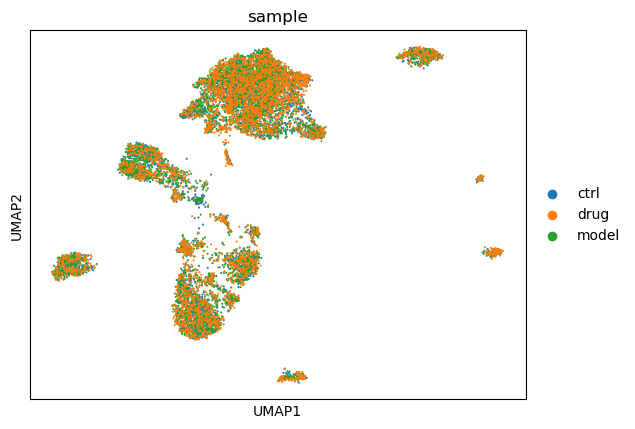

In [ ]:
# Check if integration successfully removed batch discrepancy
sc.pp.neighbors(adata, n_neighbors=260, n_pcs=30, random_state=42, use_rep="X_pca_harmony")
sc.tl.umap(adata)
sc.pl.umap(adata, color=["sample"])

/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


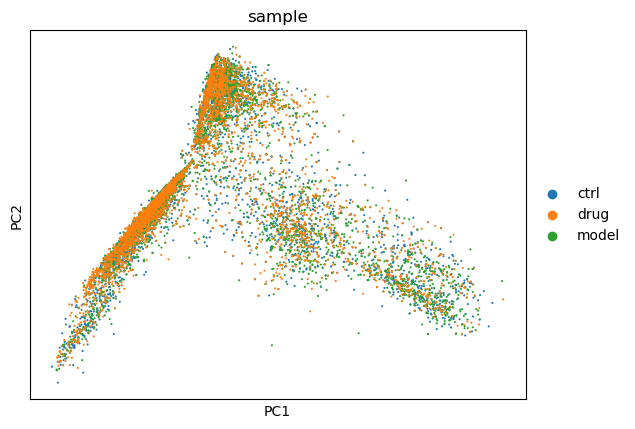

In [ ]:
# Also check if batch discrepancy contributed to the major PCA variance
sc.pl.pca(adata, color="sample")

/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/slurm/home/yrd/fanlab/gaomeng/anaconda3/envs/env/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


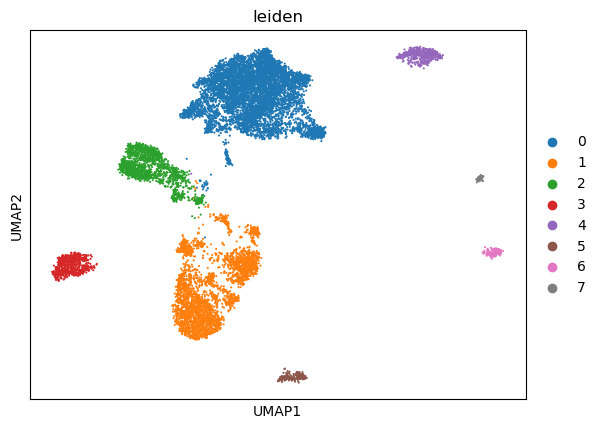

In [ ]:
# Clustering
sc.tl.leiden(adata, resolution=0.1,random_state=42)
sc.pl.umap(adata, color=["leiden"])

In [ ]:
# Cell type identification
'''
genes_of_interest = ['Aqp4', 'Gja1', 'Aldh1l1', 'Gfap', 'Slc7a10', 'Sox9',#(Astrocytes)
                     'P2ry12', 'Tmem119', 'Aif1', 'Slc2a5', 'Trem2', 'Cx3cr1', 'Itgam', 'Gpr34', 'C3ar1', 'Csf1r', 'Fcrls',#Microglia
                     'Mgl2', 'Mrc1', 'Pf4',#Macrophages
                     'Mog','Opalin', 'Mag', 'Ermn', 'Cldn11' ,#(Oligodendrocytes)
                     'Pdgfra', 'Opcml', 'Tnr', 'Myt1', #(Oligodendrocyte precursors)
                     'Kl', 'Car12', 'Ttr',# (Choroid plexus), 
                     'Ccdc153', 'Dnah11', #(Ependymal), 
                     'Cd3d', #(Lymphocytes), 
                     'Flt1', 'Emcn', 'Cldn5', 'Cdh5', 'Vwf', 'Tek', 'Cd34', #(Endothelial), 
                     'Slc47a1', 'Mgp', #(Vascular leptomeningeal), 
                     'Acta2', 'Bgn', #(Vascular smooth muscle), 
                     'Vtn', 'Kcnj8', #(Pericytes), 
                     'Dcx' #(Neuroprogenitors)
                    ]
'''
sc.pl.dotplot(adata, var_names=genes_of_interest, groupby='leiden')


In [ ]:
# Cell type annotation
'''
cluster_to_cell_type = {
   '0': 'Microglia',
   '1': 'Oligodendrocytes',
   '2': 'Astrocytes', 
   '3': 'Endothelial', 
   '4': 'Oligodendrocytes',
   '5': 'Pericytes',
   '6': 'Choroid plexus',
   '7': 'Microglia',
   '8': 'Choroid plexus',
}
'''
adata.obs["cell_type"] = adata.obs['leiden'].map(cluster_to_cell_type)

In [ ]:
# Save AnnData
adata.write("annotated_data.h5ad")

Step 2. To Calculate STARidx, we should first calculate the differentially expressed genes (DEGs) and effectively recovered gene (ERGs) for each cell type between the disease model group (group B) and the control group (group A), because only genes that were significantly perturbed by disease can be included in recovery analysis.

In [ ]:
# Use control and model groups for DEG analysis
adata_filtered = adata[adata.obs['sample'].isin(['ctrl', 'model']), :].copy()

cell_types = adata_filtered.obs['cell_type'].unique()
fold_changes = {}
log2_model_expr = {}

# Calculate differential expression for each cell type
for cell_type in cell_types:
    ctrl_cells = adata_filtered[(adata_filtered.obs['sample'] == 'ctrl') & 
                                 (adata_filtered.obs['cell_type'] == cell_type), :].X
    model_cells = adata_filtered[(adata_filtered.obs['sample'] == 'model') & 
                                  (adata_filtered.obs['cell_type'] == cell_type), :].X
    
    ctrl_mean = np.mean(ctrl_cells, axis=0) + 1
    model_mean = np.mean(model_cells, axis=0) + 1

    log2_model = np.log2(model_mean)

    log2_fc = np.log2(model_mean / ctrl_mean)

    fold_changes[cell_type] = log2_fc
    log2_model_expr[cell_type] = log2_model

log2_fc_df = pd.DataFrame(fold_changes, index=adata_filtered.var_names)
log2_fc_df['gene'] = log2_fc_df.index
log2_fc_df = log2_fc_df[['gene'] + list(cell_types)]

log2_model_expr_df = pd.DataFrame(log2_model_expr, index=adata_filtered.var_names) 
log2_model_expr_df['gene'] = log2_model_expr_df.index
log2_model_expr_df = log2_model_expr_df[['gene'] + list(cell_types)]

log2_fc_values = log2_fc_df.set_index('gene')
log2_fc_values = log2_fc_values.apply(pd.to_numeric, errors='coerce')

log2_fc_change_df = log2_fc_values.copy()
log2_fc_change_df = log2_fc_change_df.applymap(lambda x: 'up' if x > 0.1 else ('down' if x < -0.1 else 'stable'))

log2_fc_change_df.insert(0, 'gene', log2_fc_values.index)
log2_fc_change_df.head()

In [ ]:
# See how many DEGs from each cell type retained under a specific threshold

min_expr_in_model = 0
min_fc_in_model = 0

log2_fc_df = log2_fc_df.apply(pd.to_numeric, errors='coerce')
log2_model_expr_df = log2_model_expr_df.apply(pd.to_numeric, errors='coerce')

filtered_genes_by_cell_type = {}

cell_types = log2_fc_df.columns

for cell_type in cell_types:
    filtered_model_genes = log2_model_expr_df[cell_type][log2_model_expr_df[cell_type] > min_expr_in_model].dropna().index
    filtered_fc_genes = log2_fc_df[cell_type][log2_fc_df[cell_type].abs() > min_fc_in_model].dropna().index
    
    common_genes = filtered_model_genes.intersection(filtered_fc_genes)
    filtered_genes_by_cell_type[cell_type] = common_genes

gene_counts_by_cell_type = {cell_type: len(genes) for cell_type, genes in filtered_genes_by_cell_type.items()}

for cell_type, count in gene_counts_by_cell_type.items():
    print(f"{cell_type}: {count} genes")


In [ ]:
# Record DEGs and log2FC
records = []
for cell_type, gene_list in filtered_genes_by_cell_type.items():
    if cell_type not in log2_fc_df.columns:
        continue
    for gene in gene_list:
        records.append({'cell_type': cell_type, 'gene': gene})

filtered_genes_df = pd.DataFrame(records)

log2_fc_df_indexed = log2_fc_df.copy()

def get_log2_fc(row):
    try:
        return log2_fc_df_indexed.loc[row['gene'], row['cell_type']]
    except KeyError:
        return None

filtered_genes_df['log2_fc'] = filtered_genes_df.apply(get_log2_fc, axis=1)

print(filtered_genes_df)


In [ ]:
# Only use genes shared by all cell types to plot heatmap
gene_counts = filtered_genes_df['gene'].value_counts()

common_genes = gene_counts[gene_counts >= 1].index.tolist()
common_genes_df = filtered_genes_df[filtered_genes_df['gene'].isin(common_genes)]

print(common_genes_df['gene'].nunique())
print(common_genes_df.head())

In [ ]:
# Plot heatmap
heatmap_data = common_genes_df.pivot(index='gene', columns='cell_type', values='log2_fc')
heatmap_data = heatmap_data.fillna(0)

desired_order = [
    'Endothelial', 'Pericytes','Astrocytes', 'Choroid plexus',
        'Microglia','Oligodendrocytes'  
] # The order of cell types in heatmap

valid_order = [c for c in desired_order if c in heatmap_data.columns]
heatmap_data = heatmap_data[valid_order]

gene_source = common_genes_df.drop_duplicates(subset=["gene"])[["gene", "cell_type"]].set_index("gene")
cell_order_dict = {cell: i for i, cell in enumerate(valid_order)}
gene_scores = gene_source["cell_type"].map(cell_order_dict)

sorted_gene_list = []

for cell in valid_order:
    fc_values = heatmap_data[cell]

    up_genes = fc_values[fc_values > 0].sort_values(ascending=False).index.tolist()

    down_genes = fc_values[fc_values < 0].sort_values().index.tolist()

    sorted_gene_list.extend(up_genes + down_genes)

sorted_gene_list = list(OrderedDict.fromkeys(sorted_gene_list))

heatmap_data_sorted = heatmap_data.loc[sorted_gene_list, valid_order]
heatmap_data_scaled = heatmap_data_sorted.sub(
    heatmap_data_sorted.mean(axis=1), axis=0
).div(
    heatmap_data_sorted.std(axis=1), axis=0
).fillna(0)
my_cmap = LinearSegmentedColormap.from_list(
    "refined",
    ["#4063D8", "white", "#CB3C33"]
)

plt.figure(figsize=(8, 12))
sns.heatmap(
    heatmap_data_scaled,
    cmap=my_cmap,
    vmin=-2, vmax=2, center=0,
    xticklabels=True, yticklabels=False,
    cbar_kws={'label': 'Z-score (log2FC)', 'shrink': 0.6}
)

plt.title("DEG Heatmap", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("figures/heatmap_logFC_scaled.pdf", dpi=300)
plt.show()


Step 3. Now we should see how many DEGs were retained in cell-type-specific PPI networks. Recovery analysis should be performed on genes retained in PPI networks because the importance of genes can be evaluated by their degree centrality in the PPI network.

In [ ]:
# Save genes.
output_dir = "PPI_gene_lists"
os.makedirs(output_dir, exist_ok=True)

for cell_type, genes in filtered_genes_by_cell_type.items():
    file_path = os.path.join(output_dir, f"{cell_type}_PPI_genes.txt")
    with open(file_path, "w") as f:
        for gene in genes:
            f.write(gene + "\n")


In [ ]:
# Get PPI genes information
STRING_API_URL = "https://string-db.org/api/json/network"
session_id = "blvaWwIrKaF9" # Paste your session id on your browser

ppi_results = {}

for cell_type, genes in filtered_genes_by_cell_type.items():
    gene_list_str = "%0d".join(genes)

    params = {
        "identifiers": gene_list_str,
        "species": 10090,  # mouse id. If using human data, change to human id
        "required_score": 400,
        "sessionId": session_id,
    }

    response = requests.get(STRING_API_URL, params=params)

    if response.status_code == 200:
        ppi_results[cell_type] = response.json()
        print(f"{cell_type} PPI succeed!")
    else:
        print(f"{cell_type} failure, HTTP code: {response.status_code}")

    time.sleep(1)

In [ ]:
# Write PPI query results
output_folder = "PPI_result"

os.makedirs(output_folder, exist_ok=True)

for cell_type, result in ppi_results.items():
    file_path = os.path.join(output_folder, f"{cell_type}_PPI.json")
    with open(file_path, "w") as f:
        json.dump(result, f, indent=4)


In [ ]:
# Build PPI network and calculate degree centrality of each gene
ppi_folder = "PPI_result"
degree_centrality_by_cell_type = {}
for file_name in os.listdir(ppi_folder):
    if file_name.endswith("_PPI.json"):
        cell_type = file_name.replace("_PPI.json", "")
        file_path = os.path.join(ppi_folder, file_name)

        with open(file_path, "r") as f:
            ppi_data = json.load(f)

        G = nx.Graph()
        for interaction in ppi_data:
            protein1 = interaction["preferredName_A"]
            protein2 = interaction["preferredName_B"]
            G.add_edge(protein1, protein2)

        degree_centrality =  dict(G.degree())
        degree_centrality_by_cell_type[cell_type] = degree_centrality

df_list = []
for cell_type, centrality_dict in degree_centrality_by_cell_type.items():
    df = pd.DataFrame(centrality_dict.items(), columns=["Gene", "Degree Centrality"])
    df["Cell Type"] = cell_type
    df_list.append(df)

degree_centrality_df = pd.concat(df_list, ignore_index=True)
degree_centrality_df.head()

Step 4. Now as we know which genes appeared in PPI networks, we can used these genes to calculate the recovery level (RL; which we also termed "Reg" in the article), which evaluates the extent to which the drug intervetion rescued the disease-related differential expression. After RL was determined, we calculate extent of recovery (EoR), which represents whether a gene was effectively rescued, the sum of the gene recovery score (GRS) and the topology-weighted gene counts for disease-upregulated and disease-downregulated genes (GRN_up and GRN_down), finally the NRI index.

In [ ]:
# Calculate RL

rl_results = {}

for cell_type in degree_centrality_df["Cell Type"].unique():

    ppi_genes = degree_centrality_df[degree_centrality_df["Cell Type"] == cell_type]["Gene"]
    
    valid_genes = [gene for gene in ppi_genes if gene in adata.var_names]
    
    ctrl_expr = np.mean(adata[adata.obs["sample"] == "ctrl"][:, valid_genes].X, axis=0) + 1
    model_expr = np.mean(adata[adata.obs["sample"] == "model"][:, valid_genes].X, axis=0) + 1
    drug_expr = np.mean(adata[adata.obs["sample"] == "drug"][:, valid_genes].X, axis=0) + 1
    
    log_ctrl = np.log2(ctrl_expr)
    log_model = np.log2(model_expr)
    log_drug = np.log2(drug_expr)
    
    rl_values = (log_drug - log_model) / (log_ctrl - log_model)
    
    rl_results[cell_type] = pd.DataFrame({
        "Gene": valid_genes,
        "RL": rl_values
    })

rl_df = pd.concat(rl_results, keys=rl_results.keys()).reset_index()
rl_df.rename(columns={"level_0": "Cell Type"}, inplace=True)
rl_df.head()

In [ ]:
# Calculate EoR
EoR_df = pd.DataFrame(columns=["Cell Type", "Gene", "RL", "EoR", "Change"])

for cell_type in log2_fc_change_df.columns[1:]:

    up_genes = log2_fc_change_df[log2_fc_change_df[cell_type] == "up"]["gene"]
    down_genes = log2_fc_change_df[log2_fc_change_df[cell_type] == "down"]["gene"]

    selected_genes = pd.concat([up_genes, down_genes])
    
    selected_rl = rl_df[(rl_df["Cell Type"] == cell_type) & (rl_df["Gene"].isin(selected_genes))].copy()

    valid_genes = [gene for gene in selected_rl["Gene"] if gene in adata.var_names]
    if not valid_genes:
        continue
    
    ctrl_expr = np.mean(adata[adata.obs["sample"] == "ctrl"][:, valid_genes].X, axis=0) + 1
    model_expr = np.mean(adata[adata.obs["sample"] == "model"][:, valid_genes].X, axis=0) + 1
    
    log_ctrl = np.log2(ctrl_expr)
    log_model = np.log2(model_expr)

    EoR_1 = np.abs(log_model - log_ctrl)
    EoR = (EoR_1 > 0.5).astype(int)
    
    selected_rl = selected_rl[selected_rl["Gene"].isin(valid_genes)]
    selected_rl = selected_rl.set_index("Gene").loc[valid_genes].reset_index()

    selected_rl["EoR"] = EoR

    selected_rl = selected_rl[(selected_rl["EoR"] >= 0) & (selected_rl["EoR"] <= 2)]

    selected_rl["Change"] = selected_rl["Gene"].map(
        lambda g: "up" if g in up_genes.values else "down"
    )
    
    EoR_df = pd.concat([EoR_df, selected_rl])

EoR_df.reset_index(drop=True, inplace=True)

EoR_df.head()


In [ ]:
# Calculate the weighted EoR, which ranges from 0 to the degree centrality of that gene.
RR_updown = EoR_df.merge(
    degree_centrality_df[["Gene", "Cell Type","Degree Centrality"]],
    on=["Gene", "Cell Type"],   
    how="left"
)

RR_updown["RR_updown"] = RR_updown["EoR"] * RR_updown["Degree Centrality"]

print(RR_updown.head())

In [ ]:
# Combined all cell types
EoR_all_list = []

for cell_type in rl_df["Cell Type"].unique():

    sub_df = rl_df[rl_df["Cell Type"] == cell_type].copy()
    sub_df["EoR_all"] = 1 - abs(1 - sub_df["RL"])
    sub_df = sub_df[(sub_df["EoR_all"] > 0) & (sub_df["EoR_all"] < 2)]
    sub_df["Cell Type"] = cell_type

    EoR_all_list.append(sub_df[["Cell Type", "Gene", "RL", "EoR_all"]])

EoR_all_df = pd.concat(EoR_all_list, ignore_index=True)

RR_all = EoR_all_df.merge(
    degree_centrality_df[["Gene", "Cell Type", "Degree Centrality"]],
    on=["Gene", "Cell Type"],
    how="left"
)
RR_all["RR_all"] = RR_all["EoR_all"] * RR_all["Degree Centrality"]
print(RR_all.head())

In [ ]:
df_updown = RR_updown[["Cell Type", "Gene", "RR_updown"]].copy()
df_all = RR_all[["Cell Type", "Gene", "RR_all", "Degree Centrality"]].copy()

RR_df = pd.merge(df_all, df_updown, on=["Cell Type", "Gene"], how="left")
RR_df["RR_updown"] = RR_df["RR_updown"].fillna(0)
RR_df = RR_df[["Cell Type", "Gene", "RR_updown", "RR_all", "Degree Centrality"]]

RR_df['NRI'] = RR_df['RR_updown'] + RR_df['RR_all']
print(RR_df)


In [ ]:
# Construct the whole STAR-network for visualization in CytoScape
edges_list = []
node_annotations = {}

for cell_type, interactions in ppi_results.items():
    for interaction in interactions:
        protein1 = interaction["preferredName_A"]
        protein2 = interaction["preferredName_B"]
        score = interaction["score"]

        edges_list.append((protein1, protein2, score))

        if protein1 not in node_annotations:
            node_annotations[protein1] = set()
        node_annotations[protein1].add(cell_type)

        if protein2 not in node_annotations:
            node_annotations[protein2] = set()
        node_annotations[protein2].add(cell_type)

edges_df = pd.DataFrame(edges_list, columns=["source", "target", "score"])
edges_df.drop_duplicates(inplace=True)

nodes_df = pd.DataFrame([
    {"gene": gene, "cell_types": ";".join(sorted(types))}
    for gene, types in node_annotations.items()
])

output_dir = "PPI_merged_for_Cytoscape"
os.makedirs(output_dir, exist_ok=True)

edges_df.to_csv(os.path.join(output_dir, "edges.tsv"), sep="\t", index=False)
nodes_df.to_csv(os.path.join(output_dir, "nodes.tsv"), sep="\t", index=False)

In [ ]:
# Check NRI
NRI_df = RR_df.groupby('Cell Type', as_index=False)['NRI'].sum()
print(NRI_df)

Step 5. After that, we calculate the recovery in terms of cell-cell interaction (CCI) networks.

In [ ]:
# Use raw counts for CCI inference.
expression_matrix = adata.raw.X
cell_types = adata.obs['cell_type']
metadata = adata.obs[['sample', 'cell_type']]
receptor_ligand_database = "interaction_table.csv" # CCI database


In [ ]:
# Calculate CCI for each condition
drug_adata = adata[adata.obs['sample'] == 'drug'].copy()
model_adata = adata[adata.obs['sample'] == 'model'].copy()
ctrl_adata = adata[adata.obs['sample'] == 'ctrl'].copy()

print(drug_adata.shape)
print(model_adata.shape)
print(ctrl_adata.shape)

drug_results = cellphonedb(
    adata=drug_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)

model_results = cellphonedb(
    adata=model_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)

ctrl_results = cellphonedb(
    adata=ctrl_adata,
    groupby='cell_type',
    resource_name='mouseconsensus',  
    expr_prop=0.01,
    min_cells=2,
    de_method='t-test',
    n_perms=1000,
    seed=1337,
    n_jobs=1,
    verbose=True
)

In [ ]:
# Only keep significant CCI pairs
drug_results = drug_adata.uns['liana_res']
model_results = model_adata.uns['liana_res']
ctrl_results = ctrl_adata.uns['liana_res']

drug_results_filtered = drug_results[drug_results['cellphone_pvals'] < 0.05]
model_results_filtered = model_results[model_results['cellphone_pvals'] < 0.05]
ctrl_results_filtered = ctrl_results[ctrl_results['cellphone_pvals'] < 0.05]

drug_results_filtered = drug_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]
model_results_filtered = model_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]
ctrl_results_filtered = ctrl_results_filtered[['ligand', 'receptor', 'lr_means', 'source', 'target']]

merged_results = pd.merge(drug_results_filtered, model_results_filtered, on=['ligand', 'receptor', 'source', 'target'], suffixes=('_smi', '_model'))
merged_results = pd.merge(merged_results, ctrl_results_filtered, on=['ligand', 'receptor', 'source', 'target'])

merged_results['IAB_g1g2_drug'] = merged_results['lr_means_smi']
merged_results['IAB_g1g2_model'] = merged_results['lr_means_model']
merged_results['IAB_g1g2_ctrl'] = merged_results['lr_means']

In [ ]:
# Calculate CCI difference
drug_df = drug_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
drug_df.rename(columns={'lr_means': 'value'}, inplace=True)

ctrl_df = ctrl_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
ctrl_df.rename(columns={'lr_means': 'ctrl'}, inplace=True)

model_df = model_adata.uns['liana_res'].groupby(['source', 'target'])['lr_means'].mean().reset_index()
model_df.rename(columns={'lr_means': 'model'}, inplace=True)


merged_df = ctrl_df.merge(model_df, on=['source', 'target'], how='outer')
merged_df = merged_df.merge(drug_df, on=['source', 'target'], how='outer')
merged_df = merged_df.fillna(0)

merged_df['model_vs_ctrl'] = merged_df['model'] - merged_df['ctrl']
merged_df['smi_vs_ctrl'] = merged_df['smi'] - merged_df['ctrl']

model_diff_df = merged_df[merged_df['model_vs_ctrl'].abs() > 0.01][['source', 'target', 'model_vs_ctrl']]
smi_diff_df = merged_df[merged_df['smi_vs_ctrl'].abs() > 0.01][['source', 'target', 'smi_vs_ctrl']]

model_diff_df.columns = ['source', 'target', 'value']
smi_diff_df.columns = ['source', 'target', 'value']



In [ ]:
# Optional: Use spatial coordinates for CCI recovery inference
def compute_spatial_weighted_corr(adata, ligand, receptor, source_type, target_type):

    coords = adata.obsm["spatial"]
    expr = adata.to_df()
    
    A_idx = adata.obs["cell_type"] == source_type
    B_idx = adata.obs["cell_type"] == target_type

    if A_idx.sum() == 0 or B_idx.sum() == 0:
        return np.nan

    coords_A = coords[A_idx]
    coords_B = coords[B_idx]

    xa = expr.loc[A_idx, ligand].values
    yb = expr.loc[B_idx, receptor].values

    dist_matrix = cdist(coords_A, coords_B)
    h = np.median(dist_matrix)
    if h == 0:
        return np.nan

    wab = np.exp(-dist_matrix ** 2 / (2 * h ** 2))

    xw = np.sum(wab * xa[:, None]) / np.sum(wab)
    yw = np.sum(wab * yb[None, :]) / np.sum(wab)

    numerator = np.sum(wab * (xa[:, None] - xw) * (yb[None, :] - yw))
    denom_x = np.sqrt(np.sum(wab * (xa[:, None] - xw)**2))
    denom_y = np.sqrt(np.sum(wab * (yb[None, :] - yw)**2))

    if denom_x == 0 or denom_y == 0:
        return np.nan

    r = numerator / (denom_x * denom_y)
    return r

merged_results["rc_ABg1g2"] = np.nan
merged_results["rm_ABg1g2"] = np.nan
merged_results["rd_ABg1g2"] = np.nan

for i, row in merged_results.iterrows():
    ligand = row["ligand"]
    receptor = row["receptor"]
    source = row["source"]
    target = row["target"]

    try:
        rc = compute_spatial_weighted_corr(adata_ctrl, ligand, receptor, source, target)
        rm = compute_spatial_weighted_corr(adata_model, ligand, receptor, source, target)
        rd = compute_spatial_weighted_corr(adata_drug, ligand, receptor, source, target)
    except Exception as e:
        print(f"Error at row {i}: {e}")
        rc = rm = rd = np.nan

    merged_results.at[i, "rc_ABg1g2"] = rc
    merged_results.at[i, "rm_ABg1g2"] = rm
    merged_results.at[i, "rd_ABg1g2"] = rd

# Calculate the spatially weighted CCI intensity
merged_results["IsAB_g1g2_ctrl"] = merged_results["IAB_g1g2_ctrl"] * merged_results["rc_ABg1g2"]
merged_results["IsAB_g1g2_model"] = merged_results["IAB_g1g2_model"] * merged_results["rm_ABg1g2"]
merged_results["IsAB_g1g2_drug"] = merged_results["IAB_g1g2_drug"] * merged_results["rd_ABg1g2"]

In [ ]:
# Calculate the RL for CCI. Here we used the spatially weighted CCI intensity. If you do not have spatial coordinates, just replace the IsAB_g1g2_*** with the IAB_g1g2_*** in the above cell

merged_results['RLAB_g1g2'] = (merged_results['IsAB_g1g2_drug'] - merged_results['IsAB_g1g2_model']) / (merged_results['IsAB_g1g2_ctrl'] - merged_results['IsAB_g1g2_model'])
print(merged_results[['ligand', 'receptor', 'source', 'target', 'RLAB_g1g2']].head())


In [ ]:
# Calculate the EoR for CCI
merged_results['EoRCAB_g1g2'] = np.where(
    (1 - np.abs(1 - merged_results['RLAB_g1g2'])) <= 0, 
    0, 
    1
)

print(merged_results[['ligand', 'receptor', 'source', 'target', 'RLAB_g1g2', 'EoRCAB_g1g2']].head())


In [ ]:
# Construct PPI network and betweenness centrality for CCI recovery analysis
ppi_dir = "PPI_result"
ppi_graphs = {}

for file in os.listdir(ppi_dir):
    if file.endswith("_PPI.json"):
        cell_type = file.replace("_PPI.json", "")
        with open(os.path.join(ppi_dir, file)) as f:
            interactions = json.load(f)

        G = nx.Graph()
        for entry in interactions:
            g1 = entry['preferredName_A']
            g2 = entry['preferredName_B']
            score = entry.get('score', 0.0)
            G.add_edge(g1, g2, weight=score)
        
        ppi_graphs[cell_type] = G

cell_type_pairs = list(combinations(ppi_graphs.keys(), 2))

bc_results = defaultdict(dict)
for ct1, ct2 in cell_type_pairs:
    G1 = ppi_graphs[ct1]
    G2 = ppi_graphs[ct2]

    G_union = nx.compose(G1, G2)

    bc = nx.betweenness_centrality(G_union, normalized=True)
    bc_results[(ct1, ct2)] = bc

lr_centrality_scores = []

for _, row in merged_results.iterrows():
    ct_pair = tuple(sorted([row['source'], row['target']]))
    g1 = row['ligand']
    g2 = row['receptor']

    bc_dict = bc_results.get(ct_pair, {})

    bc_g1 = bc_dict.get(g1, 0.0)
    bc_g2 = bc_dict.get(g2, 0.0)

    lr_centrality_scores.append({
        'source': row['source'],
        'target': row['target'],
        'ligand': g1,
        'receptor': g2,
        'BC_AB_g1': bc_g1,
        'BC_AB_g2': bc_g2
    })
    
B_centrality_df = pd.DataFrame(lr_centrality_scores)
B_centrality_df['BC_AB_g1g2'] = (B_centrality_df['BC_AB_g1'] + B_centrality_df['BC_AB_g2']) / 2
BC_results = merged_results.merge(B_centrality_df, on=['source', 'target', 'ligand', 'receptor'], how='left')


In [ ]:
# Calculate CCRS
BC_results["CCRS_ABg1g2"] = BC_results["EoRCAB_g1g2"] * BC_results["BC_AB_g1g2"]
ccrs_df = (
    BC_results
    .groupby(['source', 'target'])
    .apply(lambda df: (df['BC_AB_g1g2'] * df['EoRCAB_g1g2']).sum())
    .reset_index(name='CCRS_AB')
)
ccrs_df_sorted = ccrs_df.sort_values(by='CCRS_AB', ascending=False)
print(ccrs_df_sorted.head(10))


In [ ]:
# Plot overall recovery of CCI intensity and compare among cell types
df_sym = pd.concat([
    ccrs_df,
    ccrs_df.rename(columns={'source': 'target', 'target': 'source'})
])
df_sym = df_sym.groupby(['source', 'target'], as_index=False).mean()

ccrs_matrix = df_sym.pivot(index='source', columns='target', values='CCRS_AB')

custom_order = [
    'Endothelial', 'Pericytes','Astrocytes', 'Choroid plexus',
        'Microglia','Oligodendrocytes'
]

ccrs_matrix = ccrs_matrix.reindex(index=custom_order, columns=custom_order)
ccrs_matrix = ccrs_matrix.fillna(0)
vmax_val = np.percentile(ccrs_matrix.values.flatten(), 95)

ccrs_norm_clip = np.clip(ccrs_matrix, None, vmax_val)
ccrs_norm_clip = (ccrs_norm_clip - ccrs_norm_clip.min().min()) / (vmax_val - ccrs_norm_clip.min().min())
my_cmap = LinearSegmentedColormap.from_list(
    "refined",
    [ "#C7E0ED", "#327DB7","#134B87", "#053061"]
)

plt.figure(figsize=(8, 7))
ax = sns.heatmap(
    ccrs_norm_clip,
    cmap=my_cmap,
    square=True,
    linewidths=0.001,
    linecolor='white',
    cbar_kws={'label': 'Normalized CCRS_AB'},
    xticklabels=True,
    yticklabels=True
)

plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.title("Normalized CCRS Heatmap (Custom Symmetric Order)", fontsize=12)
plt.tight_layout()

plt.savefig("figures/heatmap_CCRS.pdf", dpi=300)
plt.show()


In [ ]:
# Calculate STARidx by combining NRI and CCRS
ccrs_sum_by_source = ccrs_df_sorted.groupby('source')['CCRS_AB'].sum().reset_index()
ccrs_sum_by_source.columns = ['Cell Type', 'CCRS_sum']

NRI_with_CCRS = pd.merge(NRI_df, ccrs_sum_by_source, on='Cell Type', how='left')

NRI_min, NRI_max = NRI_with_CCRS['NRI'].min(), NRI_with_CCRS['NRI'].max()
CCRS_min, CCRS_max = NRI_with_CCRS['CCRS_sum'].min(), NRI_with_CCRS['CCRS_sum'].max()

NRI_with_CCRS['NRI_norm'] = (NRI_with_CCRS['NRI'] - NRI_min) / (NRI_max - NRI_min)
NRI_with_CCRS['CCRS_norm'] = (NRI_with_CCRS['CCRS_sum'] - CCRS_min) / (CCRS_max - CCRS_min)

NRI_with_CCRS['STARidx'] = 0.5* NRI_with_CCRS['NRI_norm'] + 0.5 * NRI_with_CCRS['CCRS_norm']

print(NRI_with_CCRS)

In [ ]:
# Compare STARidx among cell types
melted_data = NRI_with_CCRS.melt(id_vars="Cell Type", value_vars=["STARidx"], 
                                 var_name="Metric", value_name="Value")

custom_order = [
     'Endothelial', 'Pericytes','Astrocytes', 'Choroid plexus',
        'Microglia','Oligodendrocytes'
]

plt.figure(figsize=(10, 6))
sns.barplot(x="Cell Type", y="Value", data=melted_data, color="#44045A", order=custom_order)

plt.title("GR by Cell Type")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Step 6. Now we can export the whole STAR-network annotated by cell types, CCI pairs, etc.

In [ ]:
filtered__df = BC_results[BC_results["lr_means"] != 0]

unique_lr_pairs = BC_results[["ligand", "receptor",'source','target']].drop_duplicates().reset_index(drop=True)
merged_results["Ir"] = merged_results[["lr_means_smi", "lr_means_model", "lr_means"]].mean(axis=1)

lr_with_ir = merged_results[["ligand", "receptor", "source", "target", "Ir"]].drop_duplicates()

unique_lr_pairs = pd.merge(unique_lr_pairs, lr_with_ir, on=["ligand", "receptor", "source", "target"], how="left")
print(unique_lr_pairs.head())
print(f"filtered_df has {unique_lr_pairs.shape[0]} unique lr pairs!")


In [ ]:

nodes_df = pd.read_csv('PPI_merged_for_Cytoscape/nodes.tsv', sep='\t')

ligands = filtered__df[['ligand', 'source']].rename(columns={'ligand': 'gene', 'source': 'cell_type'})
receptors = filtered__df[['receptor', 'target']].rename(columns={'receptor': 'gene', 'target': 'cell_type'})

ligrec = pd.concat([ligands, receptors], ignore_index=True)

gene2ct = ligrec.groupby('gene')['cell_type'].apply(lambda x: ';'.join(sorted(set(x)))).reset_index()
gene2ct = gene2ct.rename(columns={'cell_type': 'cell_types'})
existing_genes = set(nodes_df['gene'])
new_genes_df = gene2ct[~gene2ct['gene'].isin(existing_genes)].copy()

for col in nodes_df.columns:
    if col not in new_genes_df.columns:
        new_genes_df[col] = None

new_genes_df = new_genes_df[nodes_df.columns]

final_nodes = pd.concat([nodes_df, new_genes_df], ignore_index=True)
final_nodes.to_csv('PPI_merged_for_Cytoscape/nodes_with_LR.tsv', sep='\t', index=False)

In [ ]:
edges_df = pd.read_csv("PPI_merged_for_Cytoscape/edges.tsv", sep="\t")

unique_lr_pairs["ligand_upper"] = unique_lr_pairs["ligand"].str.upper()
unique_lr_pairs["receptor_upper"] = unique_lr_pairs["receptor"].str.upper()
unique_lr_pairs["lr_pair"] = unique_lr_pairs.apply(
    lambda row: tuple(sorted([row["ligand_upper"], row["receptor_upper"]])), axis=1
)

ir_means = unique_lr_pairs.groupby("lr_pair")["Ir"].mean().reset_index()
ir_means.columns = ["lr_pair", "Ir_mean"]
lr_set = set(ir_means["lr_pair"])

edges_df["source_upper"] = edges_df["source"].str.upper()
edges_df["target_upper"] = edges_df["target"].str.upper()
edges_df["edge_pair"] = edges_df.apply(
    lambda row: tuple(sorted([row["source_upper"], row["target_upper"]])),
    axis=1
)

edges_df["is_LR"] = edges_df["edge_pair"].isin(lr_set)
edges_df["Edge_type"] = edges_df["is_LR"].map({True: "Ligand-Receptor", False: "PPI"})

existing_edges = set(edges_df["edge_pair"])
missing_pairs = lr_set - existing_edges

missing_edges = pd.DataFrame(
    list(missing_pairs), columns=["source", "target"]
)
missing_edges["is_LR"] = True
missing_edges["Edge_type"] = "Ligand-Receptor"
missing_edges["edge_pair"] = missing_edges.apply(
    lambda row: tuple(sorted([row["source"].upper(), row["target"].upper()])), axis=1
)

combined_edges = pd.concat([
    edges_df,
    missing_edges
], ignore_index=True)

final_edges = pd.merge(
    combined_edges,
    ir_means,
    how="left",
    left_on="edge_pair",
    right_on="lr_pair"
).drop(columns=["source_upper", "target_upper", "lr_pair", "edge_pair"])

final_edges.to_csv("PPI_merged_for_Cytoscape/edges_3.tsv", sep="\t", index=False)


We can also visualize Spatial recovery of CCI pairs.

In [ ]:
adata_model = adata[adata.obs['sample'] == 'ctrl'].copy()

ligand_gene = "Cxcl12" 
receptor_gene = "Itga4" 

coords = adata_model.obsm['spatial']
def get_expr(adata_obj, gene):
    if gene not in adata_obj.var_names:
        raise KeyError(f"{gene} is not in var_names!")
    vec = adata_obj[:, gene].X
    if hasattr(vec, "toarray"):
        vec = vec.toarray().flatten()
    else:
        vec = np.asarray(vec).flatten()
    return vec

expr_ligand = get_expr(adata_model, ligand_gene)
expr_receptor = get_expr(adata_model, receptor_gene)

k = 50
tree = cKDTree(coords)

dists, idxs = tree.query(coords, k=k)

sigma = np.median(dists)
scores = []
midpoints = []
for i in range(coords.shape[0]):
    li = expr_ligand[i]
    if li <= 0:
        continue
    neigh_idxs = idxs[i]
    neigh_dists = dists[i]
    for j_pos, d in zip(neigh_idxs, neigh_dists):
        if j_pos == i:
            continue
        rj = expr_receptor[j_pos]
        if rj <= 0:
            continue
        base = li * rj
        spatial_w = np.exp(- (d ** 2) / (2 * sigma ** 2))
        score_ij = base * spatial_w
        if score_ij <= 0:
            continue
        midpoint = (coords[i] + coords[j_pos]) / 2
        midpoints.append(midpoint)
        scores.append(score_ij)

midpoints = np.vstack(midpoints).T
scores = np.array(scores)

kde_comm = gaussian_kde(midpoints, weights=scores)
padding = 20
x_min, y_min = coords.min(axis=0) - padding
x_max, y_max = coords.max(axis=0) + padding
n_grid = 200
xgrid = np.linspace(x_min, x_max, n_grid)
ygrid = np.linspace(y_min, y_max, n_grid)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

Z_comm = kde_comm(grid_coords).reshape(n_grid, n_grid)

kde_lig = gaussian_kde(coords.T, weights=expr_ligand + 1e-8)
kde_rec = gaussian_kde(coords.T, weights=expr_receptor + 1e-8)
Z_lig = kde_lig(grid_coords).reshape(n_grid, n_grid)
Z_rec = kde_rec(grid_coords).reshape(n_grid, n_grid)

fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

cf0 = axs[0].contourf(X, Y, Z_lig, levels=20, cmap="Blues", alpha=0.7)
axs[0].scatter(coords[:,0], coords[:,1], s=5, color="black", alpha=0.2)
axs[0].set_title(f"{ligand_gene} expression hotspot")
axs[0].set_aspect("equal")
fig.colorbar(cf0, ax=axs[0], label="Density")

cf1 = axs[1].contourf(X, Y, Z_rec, levels=20, cmap="Reds", alpha=0.7)
axs[1].scatter(coords[:,0], coords[:,1], s=5, color="black", alpha=0.2)
axs[1].set_title(f"{receptor_gene} expression hotspot")
axs[1].set_aspect("equal")
fig.colorbar(cf1, ax=axs[1], label="Density")

cf2 = axs[2].contourf(X, Y, Z_comm, levels=20, cmap="Purples", alpha=0.7)
axs[2].scatter(coords[:,0], coords[:,1], s=5, color="black", alpha=0.2)
axs[2].set_title(f"Spatial-weighted CCI hotspot\n{ligand_gene}->{receptor_gene}")
axs[2].set_aspect("equal")
fig.colorbar(cf2, ax=axs[2], label="Score density")

for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
#plt.savefig("/slurm/home/yrd/fanlab/gaomeng/NRI/spatial/figures/CCI_spatial_hotpot_c.pdf", format="pdf", bbox_inches="tight")
plt.show()